## **Question**
### In a game of Blackjack, what is the probability that a player gets a total of 21 on their first two cards, given that the dealer's face-up card is an Ace?

The process is a distribution process of cards without replacement from a 52-card shuffled pack in a game of blackjack 
One card drawn for the dealer’s upcard and two different cards drawn from the remaining deck for the player’s first hand.

Getting a player total of 21 on the first two cards, conditioned on the dealer's visible card being an Ace:$$P(\text{Player 21} \mid \text{Dealer Ace}) = \frac{P(\text{Player 21 and Dealer Ace})}{P(\text{Dealer Ace})}$$

#### **Name Event**

##### Event A: The player receives a total of 21 on their first two cards.
##### Event B: The dealer's face-up card is an Ace.

##### **Identify probability type**
It asks for A given B

##### **Are they mututally exclusive?**

No, they are not mutually exclusive. If two events cannot occur at the same time, then the events are mutually exclusive ($P(A \cap B) = 0$). In this case, it is quite likely that the dealer can have an Ace while the player has an Ace and a 10-value card (21).

##### **Dependent or independent?**
No, they are dependent (not independent).
Since an Ace drawn by the dealer decreases the number of Aces left from four to three, there will be fewer opportunities for the player to draw an Ace for their 21. Since P(A\B) / P(A), the events are not independent.

In [1]:
import pandas as pd
import numpy as np
np.random.seed(42)

In [2]:
ranks = ['2', '3', '4', '5', '6', '7', '8', '9', '10', 'J', 'Q', 'K', 'A']
suits = ['Spades', 'Hearts', 'Diamonds', 'Clubs']

cards = []
for rank in ranks:
    for suit in suits:
        if rank == 'A':
            val = 11
        elif rank in ['10', 'J', 'Q', 'K']:
            val = 10
        else:
            val = int(rank)
        cards.append({'rank': rank, 'suit': suit, 'value': val})

deck_df = pd.DataFrame(cards)
deck_df.head()

,rank,suit,value
0,2,Spades,2
1,2,Hearts,2
2,2,Diamonds,2
3,2,Clubs,2
4,3,Spades,3


In [3]:
def simulate_blackjack_hands(n_trials=100000):
    draw_indices = np.empty((n_trials, 3), dtype=int)
    for i in range(n_trials):
        draw_indices[i] = np.random.choice(52, size=3, replace=False)
        
    dealer_ranks = deck_df.iloc[draw_indices[:, 0]]['rank'].values
    p1_ranks = deck_df.iloc[draw_indices[:, 1]]['rank'].values
    p1_vals = deck_df.iloc[draw_indices[:, 1]]['value'].values
    p2_ranks = deck_df.iloc[draw_indices[:, 2]]['rank'].values
    p2_vals = deck_df.iloc[draw_indices[:, 2]]['value'].values
    
    dealer_has_ace = (dealer_ranks == 'A')
    player_has_21 = ((p1_ranks == 'A') & (p2_vals == 10)) | ((p2_ranks == 'A') & (p1_vals == 10))
    
    return pd.DataFrame({
        'dealer_has_ace': dealer_has_ace,
        'player_has_21': player_has_21
    })

In [4]:
n_simulations = 100000
results_df = simulate_blackjack_hands(n_simulations)

qualifying_trials = results_df[results_df['dealer_has_ace']]

p_dealer_ace = results_df['dealer_has_ace'].mean()
p_joint = (results_df['dealer_has_ace'] & results_df['player_has_21']).mean()
p_conditional = qualifying_trials['player_has_21'].mean()

In [5]:
summary_data = {
    'Probability Type': ['P(Dealer Ace)', 'Joint P(Ace & 21)', 'Conditional P(21 | Dealer Ace)'],
    'Simulated Value': [p_dealer_ace, p_joint, p_conditional],
    'Percentage': [f"{p_dealer_ace*100:.2f}%", f"{p_joint*100:.2f}%", f"{p_conditional*100:.2f}%"]
}

summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

              Probability Type  Simulated Value Percentage
                 P(Dealer Ace)         0.077690      7.77%
             Joint P(Ace & 21)         0.003010      0.30%
Conditional P(21 | Dealer Ace)         0.038744      3.87%


##### **Ai Prompt**

Write a Monte Carlo simulation in Python using Pandas to calculate the conditional probability of a player drawing 21 given the dealer draws an Ace. Structure the output into 5 distinct Jupyter Notebook cells. Use a 52-card deck DataFrame, sample 3 cards without replacement per trial, apply boolean masking for the events, and output the probabilities in a summary DataFrame.

In [6]:
n_trials = 10000 

simulated_data = simulate_blackjack_hands(n_trials)

print(f"Total simulated trials: {len(simulated_data)}")
simulated_data.head()

Total simulated trials: 10000


,dealer_has_ace,player_has_21
0,False,False
1,False,False
2,False,True
3,False,False
4,False,False


In [7]:
dealer_ace_trials = simulated_data[simulated_data['dealer_has_ace'] == True]

total_condition_met = len(dealer_ace_trials)
print(f"Number of trials where Dealer has an Ace: {total_condition_met}")

Number of trials where Dealer has an Ace: 751


In [8]:
successful_outcomes = dealer_ace_trials[dealer_ace_trials['player_has_21'] == True]

total_successes = len(successful_outcomes)
print(f"Number of times Player got 21 WHEN Dealer had an Ace: {total_successes}")

Number of times Player got 21 WHEN Dealer had an Ace: 17


In [9]:
empirical_prob = total_successes / total_condition_met

print(f"Empirical Probability P(Player 21 | Dealer Ace): {empirical_prob:.4f}")
print(f"As a percentage: {empirical_prob * 100:.2f}%")

Empirical Probability P(Player 21 | Dealer Ace): 0.0226
As a percentage: 2.26%


##### **AI Prompt**

Write Python code using Pandas to calculate the empirical conditional probability of a player getting 21 given the dealer has an Ace, based on a simulated DataFrame. Break the response into exactly 4 Jupyter Notebook cells. Ensure the simulation uses 10,000 trials to satisfy a minimum 1,000 trial requirement. Show the explicit mathematical steps of filtering the denominator (dealer has ace) and the numerator (player has 21 within that subset) before dividing them.

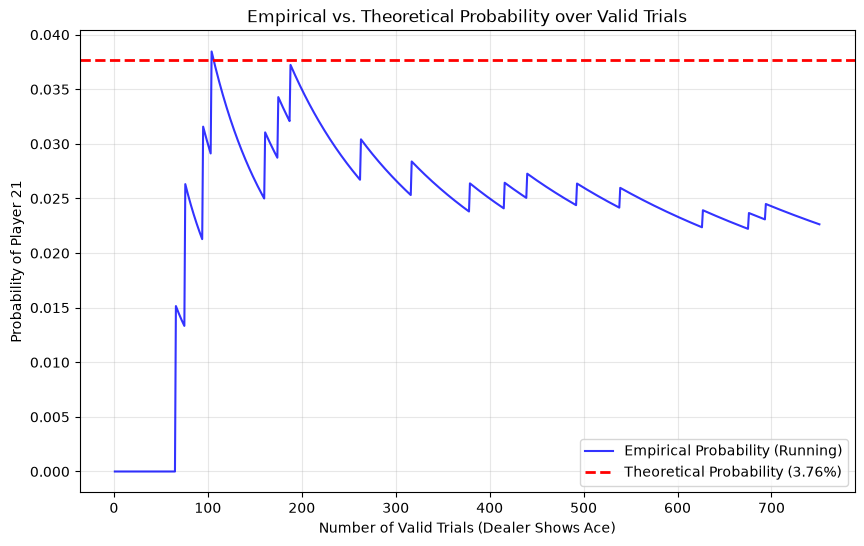

In [10]:
import matplotlib.pyplot as plt
import numpy as np

success_sequence = dealer_ace_trials['player_has_21'].values

cumulative_successes = np.cumsum(success_sequence)

cumulative_trials = np.arange(1, len(success_sequence) + 1)
running_empirical_prob = cumulative_successes / cumulative_trials
theoretical_prob = 16 / 425
plt.figure(figsize=(10, 6))
plt.plot(cumulative_trials, running_empirical_prob, 
         label='Empirical Probability (Running)', color='blue', alpha=0.8)
plt.axhline(y=theoretical_prob, color='red', linestyle='--', 
            linewidth=2, label='Theoretical Probability (3.76%)')

plt.title('Empirical vs. Theoretical Probability over Valid Trials')
plt.xlabel('Number of Valid Trials (Dealer Shows Ace)')
plt.ylabel('Probability of Player 21')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#### Conclusion

The probability of a player being dealt a hand value of 21 in a single-deck game where the dealer has an Ace showing is exactly 16/425, which comes out to be 3.76%.Since there is a visible Ace for the dealer, the number of cards in the deck available for the player would be 51. For the player to have a Blackjack, he/she will need an Ace among the three remaining and one of the ten-valued cards (10, J, Q, K), which is 16 in numbers.There are 1,275 possible two-card combinations remaining in the deck of 51 cards. Out of which, 48 combinations result in 21 ($3 \times 16$). Dividing 48 with 1,275 yields $16/425$.